# Pie of Close Values vs. Sorted Bar

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

People judge angles and areas much less accurately than lengths on a common baseline. In a pie of near-equal slices you cannot rank them or see the differences, and the many colors force the reader to keep looking back at the legend.

## When to use

- Use a sorted bar chart when the reader must compare or rank shares
- Keep pies for a single dominant share or simple 2–3 part splits seen at a glance

## Avoid when

- More than ~5 slices, or slices of similar size
- Comparing the same breakdown across several pies
- 3-D or exploded pies, which distort angles further

## Alternatives

- Sorted bar chart with direct labels
- 100% stacked bar (to compare compositions across groups)
- Waffle chart (for a single share)

## Design tips

- Sort bars by value and use one color for one series
- Label values at the bar ends so no legend lookup is needed
- If one category matters, highlight it and gray the rest

## Example

Market share of five vendors with similar shares (18–23%).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({"vendor": ["Vendor A", "Vendor B", "Vendor C", "Vendor D", "Vendor E"],
                   "share": [21.0, 19.0, 23.0, 17.5, 19.5]})
df

,vendor,share
0,Vendor A,21.0
1,Vendor B,19.0
2,Vendor C,23.0
3,Vendor D,17.5
4,Vendor E,19.5


### Plot

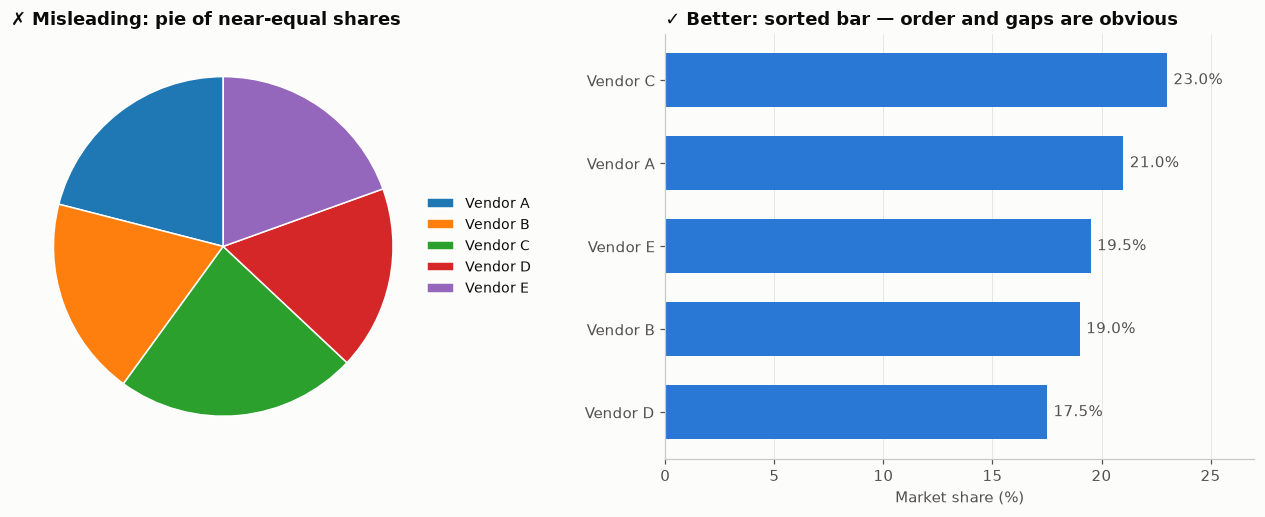

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})

# Misleading: near-equal slices, legend lookup, no order.
ax1.pie(df["share"], labels=None, colors=plt.get_cmap("tab10").colors[:5], startangle=90,
        wedgeprops=dict(edgecolor="white", linewidth=1))
ax1.legend(df["vendor"], loc="center left", bbox_to_anchor=(0.95, 0.5), fontsize=9)
ax1.set_title("✗ Misleading: pie of near-equal shares", fontsize=11.5)

# Better: sorted bar, one color, direct labels.
d = df.sort_values("share")
ax2.barh(d["vendor"], d["share"], color=PALETTE[0], height=0.65)
for y, v in enumerate(d["share"]):
    ax2.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9.5, color="#52514e")
ax2.set_xlim(0, 27)
ax2.set_xlabel("Market share (%)")
ax2.grid(axis="y", visible=False)
ax2.set_title("✓ Better: sorted bar — order and gaps are obvious", fontsize=11.5)
fig.tight_layout()
plt.show()

## How to read it

Try to rank the vendors from the pie on the left. Then look at the right, where the order (C > A > E > B > D) and the gaps of 0.5–2 points are immediately clear.

---
Standalone script: [`pie_close_values.py`](pie_close_values.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)